# Download, preparação e inspeção inicial - Azure Diabetes

Arquivo de exemplo disponibilizado pelo MicrosoftLearning para atividades do AI-900. O download usa o CSV bruto, em vez da página HTML do GitHub. Não assumimos aqui que os registros sejam representativos de uma população clínica. PatientID é um identificador, não um atributo destinado ao futuro modelo.

Fonte: [dataset original](https://github.com/MicrosoftLearning/AI-900-AIFundamentals/blob/main/data/ml/diabetes.csv).

**Objetivo:** baixar os dados, preservar os campos originais, salvar em Parquet e inspecionar sua qualidade e distribuição. Execute as células na ordem apresentada, no ambiente de `ml/`.

Este notebook é didático e não realiza diagnóstico, treinamento ou registro de modelos.

## 1. Bibliotecas e caminhos

As pastas são criadas automaticamente. O Parquet e os arquivos de origem ficam em `data/`, ignorada pelo Git.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import io
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# Funciona iniciando o Jupyter na raiz, em ml/ ou em ml/notebooks/.
def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml" / "pyproject.toml").is_file() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError("Abra o notebook dentro deste repositório.")

PROJECT_ROOT = find_project_root()

DATASET_URL = "https://raw.githubusercontent.com/MicrosoftLearning/AI-900-AIFundamentals/main/data/ml/diabetes.csv"
SOURCE_PAGE = "https://github.com/MicrosoftLearning/AI-900-AIFundamentals/blob/main/data/ml/diabetes.csv"
DATA_DIR = PROJECT_ROOT / "data" / "azure-diabetes"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "diabetes.csv"
PARQUET_PATH = DATA_DIR / "diabetes.parquet"
METADATA_PATH = DATA_DIR / "source.json"
TARGET = "Diabetic"
EXPECTED_COLUMNS = ["PatientID","Pregnancies","PlasmaGlucose","DiastolicBloodPressure","TricepsThickness","SerumInsulin","BMI","DiabetesPedigree","Age","Diabetic"]
FORCE_DOWNLOAD = False  # True para atualizar o arquivo original.
print(f"Pasta de dados: {DATA_DIR.relative_to(PROJECT_ROOT).as_posix()}")


Pasta de dados: data/azure-diabetes


## 2. Download e leitura

O arquivo existente é reutilizado. Para baixar novamente, altere `FORCE_DOWNLOAD`. O conteúdo recebido é validado antes de substituir o CSV local; uma falha de rede pode ser corrigida executando a célula novamente.

In [2]:
if FORCE_DOWNLOAD or not CSV_PATH.is_file():
    response = requests.get(DATASET_URL, timeout=(15, 60))
    response.raise_for_status()
    csv_bytes = response.content
    candidate = pd.read_csv(io.BytesIO(csv_bytes))
    if candidate.empty or list(candidate.columns) != EXPECTED_COLUMNS:
        raise ValueError("O arquivo recebido está vazio ou seu esquema mudou. Confira a fonte.")
    temporary_path = CSV_PATH.with_suffix(".csv.part")
    temporary_path.write_bytes(csv_bytes)
    temporary_path.replace(CSV_PATH)
    metadata = {
        "source_page": SOURCE_PAGE,
        "download_url": DATASET_URL,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "csv_sha256": hashlib.sha256(csv_bytes).hexdigest(),
    }
    METADATA_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Download concluído.")
else:
    print("Usando o CSV já disponível.")

data = pd.read_csv(CSV_PATH)
if data.empty or list(data.columns) != EXPECTED_COLUMNS:
    raise ValueError("CSV local vazio ou com colunas inesperadas. Confira o arquivo.")
if TARGET not in data:
    raise ValueError("Coluna alvo ausente.")
expected_classes = {0, 1}
if data[TARGET].isna().any() or set(data[TARGET].unique()) != expected_classes:
    raise ValueError("A coluna alvo contém valores ausentes ou classes inesperadas.")
display(data.head())


Usando o CSV já disponível.


,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


## 3. Preparação e salvamento em Parquet

Nesta etapa, preparação significa converter o CSV em Parquet, preservando linhas, colunas e valores. Não removemos duplicatas, imputamos ausências, codificamos categorias ou normalizamos atributos. Essas decisões ficam para os experimentos posteriores.

In [3]:
temporary_parquet = PARQUET_PATH.with_suffix(".parquet.part")
data.to_parquet(temporary_parquet, engine="pyarrow", index=False)
restored = pd.read_parquet(temporary_parquet, engine="pyarrow")
pd.testing.assert_frame_equal(data, restored)
temporary_parquet.replace(PARQUET_PATH)
print(f"Parquet salvo e conferido: {PARQUET_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"{len(data):,} registros; {len(data.columns)} colunas.")


Parquet salvo e conferido: data/azure-diabetes/diabetes.parquet
10,000 registros; 10 colunas.


## 4. Estrutura e qualidade dos dados

Observe tipos, valores ausentes e duplicatas. Registros iguais não são automaticamente erros; avalie seu significado antes de removê-los.

In [4]:
data.info()
quality = pd.DataFrame({
    "tipo": data.dtypes.astype(str),
    "ausentes": data.isna().sum(),
    "ausentes_percentual": data.isna().mean().mul(100).round(2),
    "valores_distintos": data.nunique(dropna=False),
})
display(quality)
print(f"Linhas inteiramente duplicadas: {data.duplicated().sum()}")
print(f"PatientID duplicados: {data['PatientID'].duplicated().sum()}")
print(f"Duplicatas sem considerar PatientID: {data.drop(columns='PatientID').duplicated().sum()}")
display(data.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PatientID               10000 non-null  int64  
 1   Pregnancies             10000 non-null  int64  
 2   PlasmaGlucose           10000 non-null  int64  
 3   DiastolicBloodPressure  10000 non-null  int64  
 4   TricepsThickness        10000 non-null  int64  
 5   SerumInsulin            10000 non-null  int64  
 6   BMI                     10000 non-null  float64
 7   DiabetesPedigree        10000 non-null  float64
 8   Age                     10000 non-null  int64  
 9   Diabetic                10000 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 781.4 KB


,tipo,ausentes,ausentes_percentual,valores_distintos
PatientID,int64,0,0.0,9959
Pregnancies,int64,0,0.0,15
PlasmaGlucose,int64,0,0.0,149
DiastolicBloodPressure,int64,0,0.0,90
TricepsThickness,int64,0,0.0,66
SerumInsulin,int64,0,0.0,620
BMI,float64,0,0.0,10000
DiabetesPedigree,float64,0,0.0,10000
Age,int64,0,0.0,56
Diabetic,int64,0,0.0,2


Linhas inteiramente duplicadas: 0
PatientID duplicados: 41
Duplicatas sem considerar PatientID: 0


,count,mean,std,min,25%,50%,75%,max
PatientID,10000.0,1.502122e+06,289286.764810,1.000038e+06,1.251672e+06,1.504394e+06,1.754608e+06,1.999997e+06
Pregnancies,10000.0,3.255800e+00,3.405720,0.000000e+00,0.000000e+00,2.000000e+00,6.000000e+00,1.400000e+01
PlasmaGlucose,10000.0,1.078502e+02,31.920909,4.400000e+01,8.400000e+01,1.050000e+02,1.290000e+02,1.920000e+02
DiastolicBloodPressure,10000.0,7.120750e+01,16.801478,2.400000e+01,5.800000e+01,7.200000e+01,8.500000e+01,1.170000e+02
TricepsThickness,10000.0,2.881760e+01,14.506480,7.000000e+00,1.500000e+01,3.100000e+01,4.100000e+01,9.200000e+01
SerumInsulin,10000.0,1.392436e+02,133.777919,1.400000e+01,3.900000e+01,8.500000e+01,1.970000e+02,7.960000e+02
BMI,10000.0,3.156702e+01,9.804366,1.820081e+01,2.124743e+01,3.192242e+01,3.932892e+01,5.603463e+01
DiabetesPedigree,10000.0,4.009437e-01,0.381463,7.804379e-02,1.370654e-01,1.996983e-01,6.211584e-01,2.301594e+00
Age,10000.0,3.013410e+01,12.106047,2.100000e+01,2.200000e+01,2.400000e+01,3.500000e+01,7.700000e+01
Diabetic,10000.0,3.344000e-01,0.471804,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


## 5. Balanceamento das classes

As proporções são calculadas diretamente do arquivo. O balanceamento influencia a escolha de métricas e a futura separação dos dados.

,quantidade,percentual
Não diabético,6656,66.56
Diabético,3344,33.44


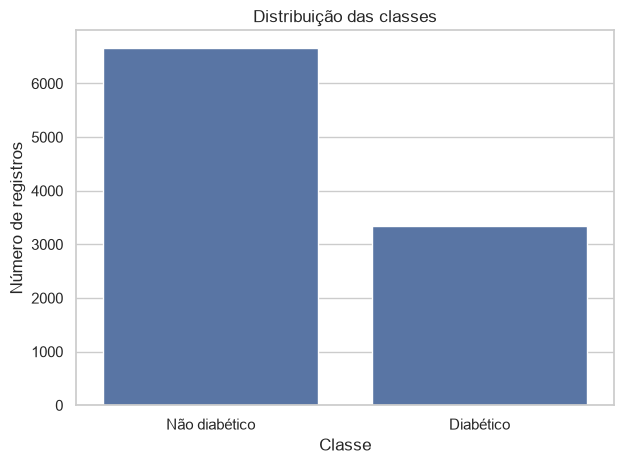

In [5]:
class_labels = {"0":"Não diabético","1":"Diabético"}
counts = data[TARGET].value_counts().sort_index()
balance = pd.DataFrame({"quantidade": counts, "percentual": counts.div(len(data)).mul(100).round(2)})
balance.index = [class_labels[str(value)] for value in balance.index]
display(balance)
ax = sns.barplot(x=balance.index, y=balance["quantidade"], color="#4c72b0")
ax.set(title="Distribuição das classes", xlabel="Classe", ylabel="Número de registros")
plt.tight_layout()
plt.show()


## 6. Distribuição das variáveis

Os gráficos são descritivos: diferenças entre grupos e correlações não demonstram causalidade.

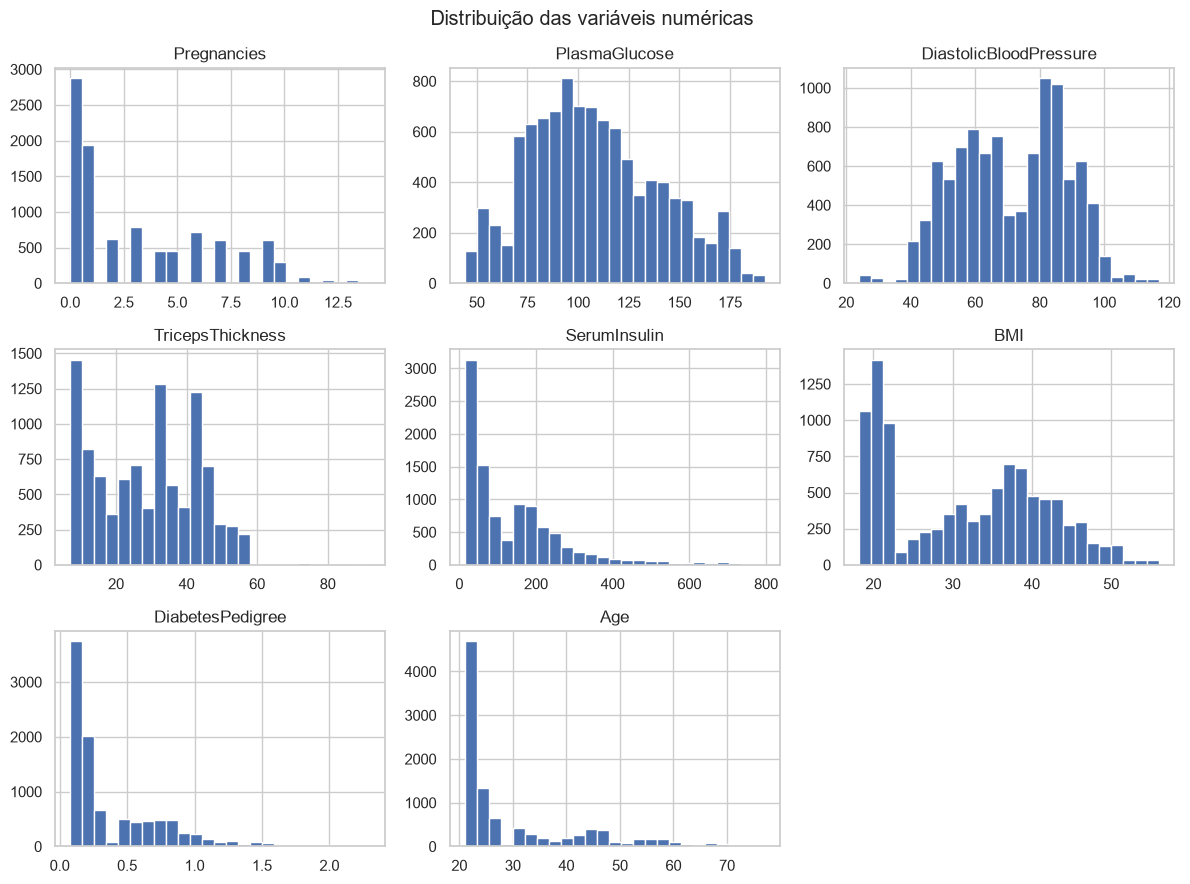

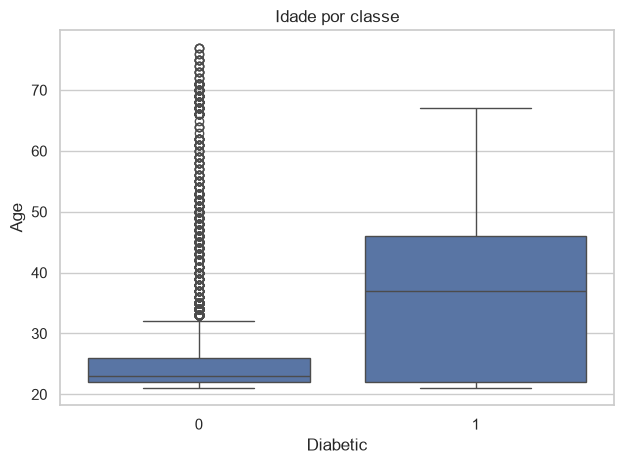

In [6]:
numeric_columns = [name for name in data.select_dtypes(include="number").columns if name not in {TARGET, "PatientID"}]
if numeric_columns:
    data[numeric_columns].hist(bins=25, figsize=(12, max(3, 3 * ((len(numeric_columns) + 2) // 3))), layout=((len(numeric_columns) + 2) // 3, 3))
    plt.suptitle("Distribuição das variáveis numéricas")
    plt.tight_layout()
    plt.show()

if "Age" in data:
    sns.boxplot(data=data, x=TARGET, y="Age")
    plt.title("Idade por classe")
    plt.tight_layout()
    plt.show()


### Zeros e correlações

Verificamos a frequência de zeros nas medidas abaixo, sem convertê-los automaticamente em valores ausentes. A interpretação exige conferir o significado de cada campo na fonte. `PatientID` é excluído da matriz de correlação.

,zeros,percentual
PlasmaGlucose,0,0.0
DiastolicBloodPressure,0,0.0
TricepsThickness,0,0.0
SerumInsulin,0,0.0
BMI,0,0.0


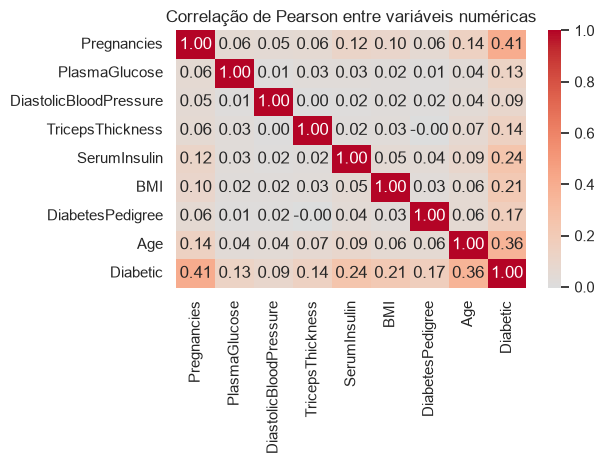

In [7]:
measurement_columns = ["PlasmaGlucose", "DiastolicBloodPressure", "TricepsThickness", "SerumInsulin", "BMI"]
zeros = data[measurement_columns].eq(0).sum()
display(pd.DataFrame({"zeros": zeros, "percentual": zeros.div(len(data)).mul(100).round(2)}))
correlation_columns = numeric_columns + [TARGET]
sns.heatmap(data[correlation_columns].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlação de Pearson entre variáveis numéricas")
plt.tight_layout()
plt.show()


## 7. Perguntas para a próxima etapa

- Há classes desbalanceadas ou padrões que merecem investigação?
- Quais campos são compreensíveis e fáceis de preencher em uma interface em português?
- Há ausências, zeros ou duplicatas que precisam de uma decisão documentada?
- Quais limitações da origem dos dados precisam acompanhar os resultados?

O Parquet produzido será a entrada para o futuro notebook de treinamento. A inspeção completa pode usar todos os dados para conhecer o arquivo; decisões de seleção de atributos e ajuste do modelo deverão preservar um conjunto de teste independente.